In [1]:
from mpl_toolkits.mplot3d import Axes3D
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt # plotting
import numpy as np # linear algebra
import os # accessing directory structure
import glob
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from torch.utils.data import DataLoader, Dataset
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from sklearn.manifold import TSNE
from PIL import Image
from torchvision import transforms


In [43]:
# for dirname, _, filenames in os.walk('/kaggle/input'):
#     for filename in filenames:
#         print(os.path.join(dirname, filename))


In [2]:

print(torch.cuda.is_available())
print(torch.cuda.device_count())
print(torch.cuda.get_device_name(0) if torch.cuda.is_available() else "No GPU")

True
2
Tesla T4


In [4]:


IMAGE_DIR = "/kaggle/input/img_align_celeba/img_align_celeba"

# DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
DEVICE = torch.device("cuda")
BATCH_SIZE = 256
LATENT_DIM = 32
RIESZ_S = 2.0
LR = 1e-3
EPOCHS = 50
HIDDEN_DIM = 400
IMAGE_SIZE = (64, 64)
IN_CHANNELS = 3
INPUT_DIM = IN_CHANNELS * IMAGE_SIZE[0] * IMAGE_SIZE[1]


In [5]:
print("Using device:", DEVICE)

Using device: cuda


In [6]:
class CelebADataset(Dataset):
    def __init__(self, image_dir, transform=None, max_images=None):
        # OLD:
        # self.image_paths = glob.glob(os.path.join(image_dir, "*.jpg"))

        # NEW:
        self.image_paths = glob.glob(os.path.join(image_dir, "*.jpg"))
        self.image_paths.sort()  # 保证顺序稳定

        if max_images is not None:
            self.image_paths = self.image_paths[:max_images]

        self.transform = transform

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        image = Image.open(img_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image


transform = transforms.Compose([
    transforms.CenterCrop(178),
    transforms.Resize(IMAGE_SIZE),
    transforms.ToTensor()
])

# OLD:
# dataset = CelebADataset(IMAGE_DIR, transform=transform, max_images=5000)
# train_loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
# print("Number of images:", len(dataset))

# NEW:
dataset = CelebADataset(IMAGE_DIR, transform=transform, max_images=10000)

# 按 80% / 20% 划分
train_size = int(0.8 * len(dataset))
test_size = len(dataset) - train_size

train_dataset, test_dataset = torch.utils.data.random_split(
    dataset,
    [train_size, test_size]
)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print("Total number of images:", len(dataset))
print("Training set size:", len(train_dataset))
print("Test set size:", len(test_dataset))

Total number of images: 10000
Training set size: 8000
Test set size: 2000


In [48]:
# def show_batch(images, n=8):
#     images = images[:n].cpu()
#     grid = torchvision.utils.make_grid(images, nrow=n, padding=2)
#     plt.figure(figsize=(16, 4))
#     plt.imshow(np.transpose(grid.numpy(), (1, 2, 0)))
#     plt.axis("off")
#     plt.show()

# sample_images = next(iter(train_loader))
# show_batch(sample_images)

In [49]:
# for batch_idx, batch in enumerate(train_loader):
#     data = batch.to(DEVICE).view(-1, INPUT_DIM)
#     print("batch size:", data.size(0))

In [9]:
# --- 1. Definizione Modello Standard VAE ---
class StandardVAE(nn.Module):
    def __init__(self):
        super(StandardVAE, self).__init__()

        # Encoder
        self.fc1 = nn.Linear(INPUT_DIM, HIDDEN_DIM)

        # Mu e log-varianza del VAE standard
        self.fc_mu = nn.Linear(HIDDEN_DIM, LATENT_DIM)
        self.fc_logvar = nn.Linear(HIDDEN_DIM, LATENT_DIM)

        # Decoder
        self.fc2 = nn.Linear(LATENT_DIM, HIDDEN_DIM)
        self.fc3 = nn.Linear(HIDDEN_DIM, INPUT_DIM)

    def encode(self, x):
        h = F.relu(self.fc1(x))
        return self.fc_mu(h), self.fc_logvar(h)

    def reparameterize(self, mu, logvar):
        if self.training:
            std = torch.exp(0.5 * logvar)
            eps = torch.randn_like(std)
            return mu + eps * std
        else:
            return mu

    def decode(self, z):
        h = F.relu(self.fc2(z))
        return torch.sigmoid(self.fc3(h))

    def forward(self, x):
        mu, logvar = self.encode(x.view(-1, INPUT_DIM))
        z = self.reparameterize(mu, logvar)
        recon = self.decode(z)
        return recon, z, mu, logvar


# --- 2. Loss Function (ELBO) ---
def loss_function(recon_x, x, mu, logvar):
    mse = F.mse_loss(recon_x, x, reduction='sum')
    kld = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return mse + kld


# --- 3. Training Loop ---
def train_standard_vae():
    print(f"Start Training Standard VAE on {DEVICE}...")

    model = StandardVAE().to(DEVICE)
    optimizer = optim.Adam(model.parameters(), lr=LR)

    model.train()

    for epoch in range(EPOCHS):
        total_loss = 0

        for batch_idx, batch in enumerate(train_loader):
            # CelebADataset restituisce direttamente immagini
            data = batch.to(DEVICE).view(-1, INPUT_DIM)

            optimizer.zero_grad()

            recon, z, mu, logvar = model(data)
            loss = loss_function(recon, data, mu, logvar)

            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        avg_loss = total_loss / len(train_loader.dataset)
        print(f"Epoch {epoch+1}/{EPOCHS} | Loss (ELBO): {avg_loss:.4f}")

    print("Training completato.")
    return model


# --- Esecuzione ---
model_v = train_standard_vae()

Start Training Standard VAE on cuda...
Epoch 1/50 | Loss (ELBO): 849.1500
Epoch 2/50 | Loss (ELBO): 570.5027
Epoch 3/50 | Loss (ELBO): 481.8782
Epoch 4/50 | Loss (ELBO): 434.3132
Epoch 5/50 | Loss (ELBO): 405.6066
Epoch 6/50 | Loss (ELBO): 386.4062
Epoch 7/50 | Loss (ELBO): 381.4172
Epoch 8/50 | Loss (ELBO): 355.1493
Epoch 9/50 | Loss (ELBO): 338.7333
Epoch 10/50 | Loss (ELBO): 325.7173
Epoch 11/50 | Loss (ELBO): 318.4023
Epoch 12/50 | Loss (ELBO): 313.2185
Epoch 13/50 | Loss (ELBO): 304.4747
Epoch 14/50 | Loss (ELBO): 297.9019
Epoch 15/50 | Loss (ELBO): 295.8529
Epoch 16/50 | Loss (ELBO): 296.4664
Epoch 17/50 | Loss (ELBO): 286.7361
Epoch 18/50 | Loss (ELBO): 279.9713
Epoch 19/50 | Loss (ELBO): 276.8902
Epoch 20/50 | Loss (ELBO): 275.9706
Epoch 21/50 | Loss (ELBO): 273.8689
Epoch 22/50 | Loss (ELBO): 269.3734
Epoch 23/50 | Loss (ELBO): 267.0281
Epoch 24/50 | Loss (ELBO): 263.7488
Epoch 25/50 | Loss (ELBO): 260.4483
Epoch 26/50 | Loss (ELBO): 263.2631
Epoch 27/50 | Loss (ELBO): 257.375

In [51]:
# # --- 1. Loss: Riesz s-kernel Energy ---
# def riesz_energy_loss(z):
#     dists = torch.pdist(z, p=2) 
#     energy = 1.0 / (dists.pow(RIESZ_S) + 1e-6)
#     return energy.mean()

# # --- 2. Modello Autoencoder Sferico (Geodesico) ---
# class GeodesicSphericalVAE(nn.Module):
#     def __init__(self):
#         super().__init__()
        
#         # Encoder
#         self.fc1 = nn.Linear(784, HIDDEN_DIM)
#         self.fc_mu = nn.Linear(HIDDEN_DIM, LATENT_DIM)

        
#         # Decoder
#         self.fc2 = nn.Linear(LATENT_DIM, HIDDEN_DIM)
#         self.fc3 = nn.Linear(HIDDEN_DIM, 784)

#     def encode(self, x):
#         h = F.relu(self.fc1(x))
        
#         # 1. Mu deve stare sulla sfera
#         mu = F.normalize(self.fc_mu(h), p=2, dim=1)
        
#         # 2. Alpha: limitato a ~45 gradi (1.57 / 2 = 0.785 rad)
#         alpha = 0.3
#         return mu, alpha

#     def reparameterize(self, mu, alpha):
#         if self.training:
#             # 1. Generiamo una direzione casuale 'v'
#             v = torch.randn_like(mu)
            
#             # 2. Rendiamo v perpendicolare a mu (Gram-Schmidt)
#             v_orth = v - (v * mu).sum(dim=1, keepdim=True) * mu
#             v_tangent = F.normalize(v_orth, p=2, dim=1)
            
#             # 3. Scegliamo quanto spostarci (theta) tra 0 e alpha
#             theta = alpha * torch.rand(mu.size(0), 1, device=mu.device)
            
#             # 4. Rotazione (Rodrigues semplificato)
#             z = mu * torch.cos(theta) + v_tangent * torch.sin(theta)
#             return z 
#         else:
#             return mu

#     def decode(self, z):
#         h = F.relu(self.fc2(z))
#         return torch.sigmoid(self.fc3(h))

#     def forward(self, x):
#         mu, alpha = self.encode(x.view(-1, 784))
#         z = self.reparameterize(mu, alpha)
#         recon = self.decode(z)
#         return recon, z

# # --- 3. Training Loop ---
# def main():
#     print(f"Esecuzione su: {DEVICE} con MNIST")
    

#     model = GeodesicSphericalVAE().to(DEVICE)
#     optimizer = optim.Adam(model.parameters(), lr=LR)

#     model.train()
#     for epoch in range(EPOCHS):
#         total_rec = 0
#         total_riesz = 0
        
#         # Warm-up lineare
#         beta = 0.05 * epoch
        
#         for batch_idx, (data, _) in enumerate(train_loader):
#             data = data.to(DEVICE).view(-1, 784)
#             optimizer.zero_grad()
            
#             # Otteniamo anche alpha dall'output del modello
#             recon, z = model(data)
            
#             # Loss A: Ricostruzione
#             loss_recon = F.mse_loss(recon, data, reduction='sum') / BATCH_SIZE
            
#             # Loss B: Riesz Energy
#             loss_riesz = riesz_energy_loss(z)
            
#             loss = loss_recon + (beta * loss_riesz)
            
#             loss.backward()
#             optimizer.step()
            
#             total_rec += loss_recon.item()
#             total_riesz += loss_riesz.item()
            
#             # Accumuliamo la media di alpha del batch corrente

#         # Calcolo medie per epoca
#         avg_rec = total_rec / len(train_loader)
#         avg_riesz = total_riesz / len(train_loader)
        
#         print(f"Epoch {epoch+1}/{EPOCHS} | Recon: {avg_rec:.2f} | Riesz: {avg_riesz:.4f} | Beta: {beta:.2f}")

#     return model


# model_s = main()

In [2]:
# # --- 1. Loss: Riesz s-kernel Energy ---
# def riesz_energy_loss(z):
#     dists = torch.pdist(z, p=2)
#     energy = 1.0 / (dists.pow(RIESZ_S) + 1e-6)
#     return energy.mean()

# # --- 2. Modello Autoencoder Sferico (Geodesico) ---
# class GeodesicSphericalVAE(nn.Module):
#     def __init__(self):
#         super().__init__()

#         # Encoder
#         self.fc1 = nn.Linear(INPUT_DIM, HIDDEN_DIM)
#         self.fc_mu = nn.Linear(HIDDEN_DIM, LATENT_DIM)

#         # Decoder
#         self.fc2 = nn.Linear(LATENT_DIM, HIDDEN_DIM)
#         self.fc3 = nn.Linear(HIDDEN_DIM, INPUT_DIM)

#     def encode(self, x):
#         h = F.relu(self.fc1(x))

#         # Mu sulla sfera
#         mu = F.normalize(self.fc_mu(h), p=2, dim=1)

#         alpha = 0.3
#         return mu, alpha

#     def reparameterize(self, mu, alpha):
#         if self.training:
#             v = torch.randn_like(mu)

#             # Gram-Schmidt
#             v_orth = v - (v * mu).sum(dim=1, keepdim=True) * mu
#             v_tangent = F.normalize(v_orth, p=2, dim=1)

#             theta = alpha * torch.rand(mu.size(0), 1, device=mu.device)

#             z = mu * torch.cos(theta) + v_tangent * torch.sin(theta)
#             return z
#         else:
#             return mu

#     def decode(self, z):
#         h = F.relu(self.fc2(z))
#         return torch.sigmoid(self.fc3(h))

#     def forward(self, x):
#         mu, alpha = self.encode(x.view(-1, INPUT_DIM))
#         z = self.reparameterize(mu, alpha)
#         recon = self.decode(z)
#         return recon, z

# # --- 3. Training Loop ---
# def main():
#     print(f"Esecuzione su: {DEVICE}")

#     model = GeodesicSphericalVAE().to(DEVICE)
#     optimizer = optim.Adam(model.parameters(), lr=LR)

#     model.train()
#     for epoch in range(EPOCHS):
#         total_rec = 0
#         total_riesz = 0

#         beta = 0.05 * epoch

#         for batch_idx, batch in enumerate(train_loader):
#             data = batch[0].to(DEVICE).view(-1, INPUT_DIM)
#             optimizer.zero_grad()

#             recon, z = model(data)

#             loss_recon = F.mse_loss(recon, data, reduction='sum') / BATCH_SIZE
#             loss_riesz = riesz_energy_loss(z)

#             loss = loss_recon + (beta * loss_riesz)

#             loss.backward()
#             optimizer.step()

#             total_rec += loss_recon.item()
#             total_riesz += loss_riesz.item()

#         avg_rec = total_rec / len(train_loader)
#         avg_riesz = total_riesz / len(train_loader)

#         print(f"Epoch {epoch+1}/{EPOCHS} | Recon: {avg_rec:.2f} | Riesz: {avg_riesz:.4f} | Beta: {beta:.2f}")

#     return model

# model_s = main()


NameError: name 'nn' is not defined

In [7]:
# --- 1. Loss: Riesz s-kernel Energy ---
def riesz_energy_loss(z):
    # Se il batch contiene meno di 2 punti, non si può calcolare pdist
    if z.size(0) < 2:
        return torch.tensor(0.0, device=z.device)

    dists = torch.pdist(z, p=2)

    # Protezione numerica
    dists = torch.clamp(dists, min=1e-6)

    energy = 1.0 / dists.pow(RIESZ_S)
    return energy.mean()


# --- 2. Modello Autoencoder Sferico (Geodesico) ---
class GeodesicSphericalVAE(nn.Module):
    def __init__(self):
        super().__init__()

        # Encoder
        self.fc1 = nn.Linear(INPUT_DIM, HIDDEN_DIM)
        self.fc_mu = nn.Linear(HIDDEN_DIM, LATENT_DIM)

        # Decoder
        self.fc2 = nn.Linear(LATENT_DIM, HIDDEN_DIM)
        self.fc3 = nn.Linear(HIDDEN_DIM, INPUT_DIM)

    def encode(self, x):
        h = F.relu(self.fc1(x))

        # Mu sulla sfera
        mu = F.normalize(self.fc_mu(h), p=2, dim=1)

        alpha = 0.3
        return mu, alpha

    def reparameterize(self, mu, alpha):
        if self.training:
            v = torch.randn_like(mu)

            # Gram-Schmidt
            v_orth = v - (v * mu).sum(dim=1, keepdim=True) * mu
            v_tangent = F.normalize(v_orth, p=2, dim=1)

            theta = alpha * torch.rand(mu.size(0), 1, device=mu.device)

            z = mu * torch.cos(theta) + v_tangent * torch.sin(theta)
            return z
        else:
            return mu

    def decode(self, z):
        h = F.relu(self.fc2(z))
        return torch.sigmoid(self.fc3(h))

    def forward(self, x):
        mu, alpha = self.encode(x.view(-1, INPUT_DIM))
        z = self.reparameterize(mu, alpha)
        recon = self.decode(z)
        return recon, z


# --- 3. Training Loop ---
def main():
    print(f"Esecuzione su: {DEVICE}")

    model = GeodesicSphericalVAE().to(DEVICE)
    optimizer = optim.Adam(model.parameters(), lr=LR)

    model.train()
    for epoch in range(EPOCHS):
        total_rec = 0
        total_riesz = 0

        beta = 0.05 * epoch

        for batch_idx, batch in enumerate(train_loader):
            # CelebADataset restituisce direttamente immagini
            data = batch.to(DEVICE).view(-1, INPUT_DIM)
            optimizer.zero_grad()

            recon, z = model(data)

            loss_recon = F.mse_loss(recon, data, reduction='sum') / data.size(0)
            loss_riesz = riesz_energy_loss(z)

            loss = loss_recon + (beta * loss_riesz)

            loss.backward()
            optimizer.step()

            total_rec += loss_recon.item()
            total_riesz += loss_riesz.item()

        avg_rec = total_rec / len(train_loader)
        avg_riesz = total_riesz / len(train_loader)

        print(f"Epoch {epoch+1}/{EPOCHS} | Recon: {avg_rec:.2f} | Riesz: {avg_riesz:.4f} | Beta: {beta:.2f}")

    return model


model_s = main()

Esecuzione su: cuda
Epoch 1/50 | Recon: 906.40 | Riesz: 16.1521 | Beta: 0.00
Epoch 2/50 | Recon: 650.86 | Riesz: 3.8976 | Beta: 0.05
Epoch 3/50 | Recon: 584.17 | Riesz: 2.2946 | Beta: 0.10
Epoch 4/50 | Recon: 518.75 | Riesz: 1.6436 | Beta: 0.15
Epoch 5/50 | Recon: 475.81 | Riesz: 1.5998 | Beta: 0.20
Epoch 6/50 | Recon: 443.83 | Riesz: 1.3715 | Beta: 0.25
Epoch 7/50 | Recon: 425.46 | Riesz: 1.3553 | Beta: 0.30
Epoch 8/50 | Recon: 409.66 | Riesz: 1.1780 | Beta: 0.35
Epoch 9/50 | Recon: 389.88 | Riesz: 1.1158 | Beta: 0.40
Epoch 10/50 | Recon: 374.35 | Riesz: 1.0064 | Beta: 0.45
Epoch 11/50 | Recon: 363.07 | Riesz: 0.9765 | Beta: 0.50
Epoch 12/50 | Recon: 357.05 | Riesz: 0.9651 | Beta: 0.55
Epoch 13/50 | Recon: 347.52 | Riesz: 0.9353 | Beta: 0.60
Epoch 14/50 | Recon: 340.60 | Riesz: 0.9043 | Beta: 0.65
Epoch 15/50 | Recon: 333.02 | Riesz: 0.8653 | Beta: 0.70
Epoch 16/50 | Recon: 319.18 | Riesz: 0.8000 | Beta: 0.75
Epoch 17/50 | Recon: 306.93 | Riesz: 0.7685 | Beta: 0.80
Epoch 18/50 | Recon

Generazione del confronto tra le ricostruzioni...


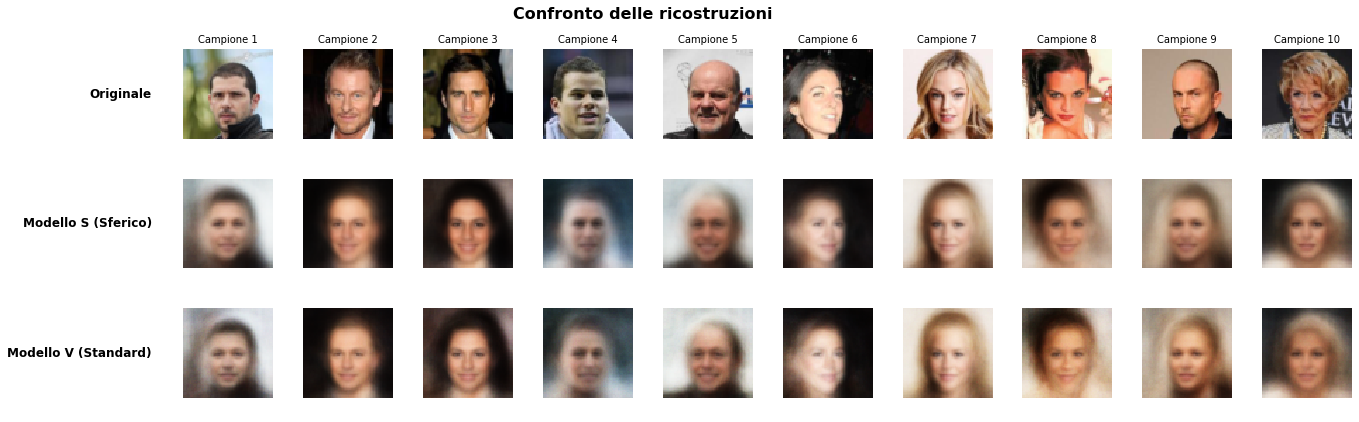

In [10]:
def visualizza_confronto_doppio(model_s, model_v, device, n_images=10):
    """
    Confronta le ricostruzioni di due modelli diversi.
    Riga 1: immagini originali
    Riga 2: ricostruzioni del modello sferico
    Riga 3: ricostruzioni del VAE standard
    """
    print("Generazione del confronto tra le ricostruzioni...")

    # Per CelebA il DataLoader restituisce direttamente un batch di immagini
    batch = next(iter(test_loader))
    data = batch.to(device)[:n_images]

    model_s.eval()
    model_v.eval()

    with torch.no_grad():
        recon_s, *rest = model_s(data)
        recon_v, *rest = model_v(data)

    data = data.cpu()

    if recon_s.ndim == 2:
        recon_s = recon_s.cpu().view(-1, IN_CHANNELS, IMAGE_SIZE[0], IMAGE_SIZE[1])
    else:
        recon_s = recon_s.cpu()

    if recon_v.ndim == 2:
        recon_v = recon_v.cpu().view(-1, IN_CHANNELS, IMAGE_SIZE[0], IMAGE_SIZE[1])
    else:
        recon_v = recon_v.cpu()

    n_show = data.size(0)
    fig, axes = plt.subplots(3, n_show, figsize=(2 * n_show, 6))

    if n_show == 1:
        axes = np.expand_dims(axes, axis=1)

    row_titles = ["Originale", "Modello S (Sferico)", "Modello V (Standard)"]

    for i in range(n_show):
        img_orig = data[i].permute(1, 2, 0).clamp(0, 1).numpy()
        axes[0, i].imshow(img_orig)
        axes[0, i].axis("off")

        img_s = recon_s[i].permute(1, 2, 0).clamp(0, 1).numpy()
        axes[1, i].imshow(img_s)
        axes[1, i].axis("off")

        img_v = recon_v[i].permute(1, 2, 0).clamp(0, 1).numpy()
        axes[2, i].imshow(img_v)
        axes[2, i].axis("off")

        axes[0, i].set_title(f"Campione {i+1}", fontsize=10)

    for r in range(3):
        axes[r, 0].text(
            -0.35, 0.5, row_titles[r],
            transform=axes[r, 0].transAxes,
            fontsize=12,
            fontweight='bold',
            va='center',
            ha='right'
        )

    plt.suptitle("Confronto delle ricostruzioni", fontsize=16, fontweight='bold')
    plt.tight_layout(rect=[0.05, 0, 1, 0.95])
    plt.show()

visualizza_confronto_doppio(model_s, model_v, DEVICE, n_images=10)

Generazione di 10 nuove immagini da rumore casuale (Dim=32)...


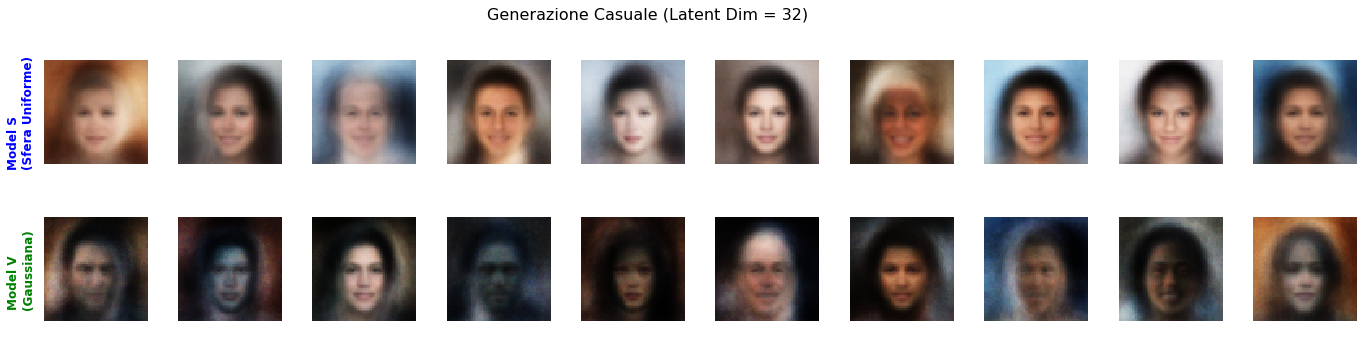

In [11]:
def visualizza_generazione_casuale(model_s, model_v, device, latent_dim, n_images=10):
    """
    Genera immagini da rumore casuale.
    - Model S: campionamento uniforme sulla sfera
    - Model V: campionamento gaussiano standard
    """
    print(f"Generazione di {n_images} nuove immagini da rumore casuale (Dim={latent_dim})...")

    model_s.eval()
    model_v.eval()

    # Campionamento latente
    z_s_raw = torch.randn(n_images, latent_dim).to(device)
    z_s = F.normalize(z_s_raw, p=2, dim=1)

    z_v = torch.randn(n_images, latent_dim).to(device)

    # Decodifica
    with torch.no_grad():
        gen_s = model_s.decode(z_s).cpu()
        gen_v = model_v.decode(z_v).cpu()

    # Se il decoder restituisce output flattenato, lo rimodella
    if gen_s.ndim == 2:
        gen_s = gen_s.view(-1, IN_CHANNELS, IMAGE_SIZE[0], IMAGE_SIZE[1])

    if gen_v.ndim == 2:
        gen_v = gen_v.view(-1, IN_CHANNELS, IMAGE_SIZE[0], IMAGE_SIZE[1])

    fig, axes = plt.subplots(2, n_images, figsize=(2 * n_images, 5))

    if n_images == 1:
        axes = np.expand_dims(axes, axis=1)

    for i in range(n_images):
        # Riga 1: modello sferico
        img_s = gen_s[i].permute(1, 2, 0).clamp(0, 1).numpy()
        axes[0, i].imshow(img_s)
        axes[0, i].axis('off')

        # Riga 2: VAE standard
        img_v = gen_v[i].permute(1, 2, 0).clamp(0, 1).numpy()
        axes[1, i].imshow(img_v)
        axes[1, i].axis('off')

    # Etichette a sinistra
    axes[0, 0].text(
        -0.35, 0.5, "Model S\n(Sfera Uniforme)",
        transform=axes[0, 0].transAxes,
        fontsize=12,
        rotation=90,
        verticalalignment='center',
        fontweight='bold',
        color='blue'
    )

    axes[1, 0].text(
        -0.35, 0.5, "Model V\n(Gaussiana)",
        transform=axes[1, 0].transAxes,
        fontsize=12,
        rotation=90,
        verticalalignment='center',
        fontweight='bold',
        color='green'
    )

    plt.suptitle(f"Generazione Casuale (Latent Dim = {latent_dim})", fontsize=16)
    plt.tight_layout(rect=[0.05, 0, 1, 0.93])
    plt.show()


visualizza_generazione_casuale(model_s, model_v, DEVICE, LATENT_DIM)

Estrazione vettori latenti dal dataset...
Calcolo PCA su 2000 punti...


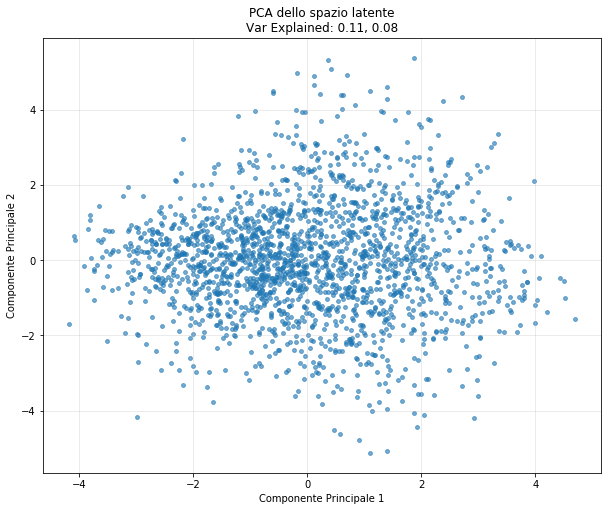

In [55]:
def visualizza_pca_training(model, device, num_points=5000):
    print("Estrazione vettori latenti dal dataset...")
    model.eval()

    loader = test_loader
    all_z = []
    count = 0

    with torch.no_grad():
        for batch in loader:
            # Per CelebA il loader restituisce direttamente le immagini
            if isinstance(batch, (list, tuple)):
                data = batch[0]
            else:
                data = batch

            data = data.to(device)

            # Se il modello è fully connected, fa il flatten
            # Se il modello è CNN, il controllo ndim dentro encode/forward gestirà il formato
            if hasattr(model, "fc1"):
                data_input = data.view(data.size(0), -1)
            else:
                data_input = data

            # encode può restituire (mu, logvar) oppure (mu, alpha)
            mu, *rest = model.encode(data_input)

            all_z.append(mu.cpu().numpy())

            count += data.size(0)
            if count >= num_points:
                break

    X = np.concatenate(all_z, axis=0)[:num_points]

    print(f"Calcolo PCA su {X.shape[0]} punti...")

    pca = PCA(n_components=2)
    X_pca = pca.fit_transform(X)

    plt.figure(figsize=(10, 8))
    plt.scatter(X_pca[:, 0], X_pca[:, 1], alpha=0.6, s=15)

    var_ratio = pca.explained_variance_ratio_
    plt.title(f'PCA dello spazio latente\nVar Explained: {var_ratio[0]:.2f}, {var_ratio[1]:.2f}')
    plt.xlabel('Componente Principale 1')
    plt.ylabel('Componente Principale 2')
    plt.grid(True, alpha=0.3)
    plt.show()


visualizza_pca_training(model_v, DEVICE)

Confronto Interpolazione: SLERP (Sferico) vs LERP (VAE)...


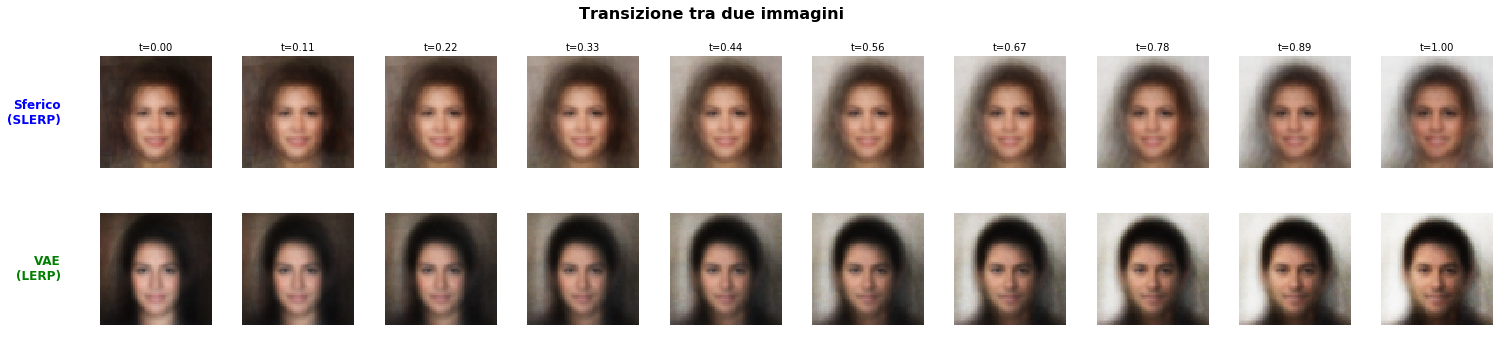

In [56]:


# def slerp(val, low, high):
#     """Spherical Linear Interpolation"""
#     omega = torch.acos(torch.clamp(torch.sum(low/torch.norm(low) * high/torch.norm(high)), -1, 1))
#     so = torch.sin(omega)
#     if so == 0:
#         return (1.0-val) * low + val * high # Fallback lineare se sono paralleli
#     return torch.sin((1.0-val)*omega) / so * low + torch.sin(val*omega) / so * high

# def lerp(val, low, high):
#     """Linear Interpolation (Standard)"""
#     return (1.0 - val) * low + val * high

# def visualizza_interpolazione(model_s, model_v, device, steps=10):
#     print("Confronto Interpolazione: Slerp (Sferico) vs Lerp (VAE)...")

#     # Prendiamo due immagini dal test set: Start e End
#     loader = test_loader
#     images, _ = next(iter(loader))
#     img1, img2 = images[0].to(device), images[1].to(device)

#     model_s.eval()
#     model_v.eval()

#     with torch.no_grad():
#         # Encoding
#         # Nota: model_s restituisce (recon, z, ...). Prendiamo z [index 1]
#         z1_s = model_s.encode(img1.view(-1, INPUT_DIM))[0] # Prende mu
#         z2_s = model_s.encode(img2.view(-1, INPUT_DIM))[0]

#         z1_v = model_v.encode(img1.view(-1, INPUT_DIM))[0] # Prende mu
#         z2_v = model_v.encode(img2.view(-1, INPUT_DIM))[0]

#         # Generazione step intermedi
#         ratios = np.linspace(0, 1, steps)

#         pics_s = []
#         pics_v = []

#         for r in ratios:
#             # Sferico -> SLERP
#             z_interp_s = slerp(r, z1_s, z2_s)
#             pics_s.append(model_s.decode(z_interp_s).cpu().view(3, 28, 28).permute(1, 2, 0))

#             # VAE -> LERP
#             z_interp_v = lerp(r, z1_v, z2_v)
#             pics_v.append(model_v.decode(z_interp_v).cpu().view(3, 28, 28).permute(1, 2, 0))

#     # Plotting
#     fig, axes = plt.subplots(2, steps, figsize=(20, 4))

#     for i in range(steps):
#         axes[0, i].imshow(pics_s[i], cmap='gray')
#         axes[0, i].axis('off')
#         axes[1, i].imshow(pics_v[i], cmap='gray')
#         axes[1, i].axis('off')

#     axes[0, 0].text(-5, 14, "Sferico\n(Slerp)", fontsize=14, rotation=90, verticalalignment='center', color='blue')
#     axes[1, 0].text(-5, 14, "VAE\n(Lerp)", fontsize=14, rotation=90, verticalalignment='center', color='green')

#     plt.suptitle("Transizione tra due immagini", fontsize=16)
#     plt.show()

# # Esegui (dopo aver addestrato su FashionMNIST per risultati migliori)
# visualizza_interpolazione(model_s, model_v, DEVICE)
def slerp(val, low, high):
    """Interpolazione lineare sferica"""
    omega = torch.acos(
        torch.clamp(
            torch.sum(low / torch.norm(low) * high / torch.norm(high)),
            -1, 1
        )
    )
    so = torch.sin(omega)

    if so == 0:
        return (1.0 - val) * low + val * high

    return (
        torch.sin((1.0 - val) * omega) / so * low
        + torch.sin(val * omega) / so * high
    )

def lerp(val, low, high):
    """Interpolazione lineare standard"""
    return (1.0 - val) * low + val * high

def visualizza_interpolazione(model_s, model_v, device, steps=10):
    """
    Confronta l'interpolazione tra due immagini:
    - Modello sferico: SLERP
    - VAE standard: LERP
    """
    print("Confronto Interpolazione: SLERP (Sferico) vs LERP (VAE)...")

    loader = test_loader
    batch = next(iter(loader))

    # Per CelebA il loader restituisce direttamente immagini
    if isinstance(batch, (list, tuple)):
        images = batch[0]
    else:
        images = batch

    if images.size(0) < 2:
        raise ValueError("Il batch deve contenere almeno 2 immagini per l'interpolazione.")

    img1 = images[0].to(device)
    img2 = images[1].to(device)

    model_s.eval()
    model_v.eval()

    with torch.no_grad():
        # --- Encoding ---
        # Compatibilità con fully connected e CNN
        if img1.ndim == 3:
            img1_batch = img1.unsqueeze(0)
            img2_batch = img2.unsqueeze(0)
        else:
            img1_batch = img1
            img2_batch = img2

        # Se il modello è fully connected, fa il flatten
        if hasattr(model_s, "fc1"):
            z1_s = model_s.encode(img1_batch.view(-1, INPUT_DIM))[0]
            z2_s = model_s.encode(img2_batch.view(-1, INPUT_DIM))[0]
        else:
            z1_s = model_s.encode(img1_batch)[0]
            z2_s = model_s.encode(img2_batch)[0]

        if hasattr(model_v, "fc1"):
            z1_v = model_v.encode(img1_batch.view(-1, INPUT_DIM))[0]
            z2_v = model_v.encode(img2_batch.view(-1, INPUT_DIM))[0]
        else:
            z1_v = model_v.encode(img1_batch)[0]
            z2_v = model_v.encode(img2_batch)[0]

        ratios = np.linspace(0, 1, steps)
        pics_s = []
        pics_v = []

        for r in ratios:
            # Sferico -> SLERP
            z_interp_s = slerp(r, z1_s, z2_s)
            img_s = model_s.decode(z_interp_s).cpu()

            if img_s.ndim == 2:
                img_s = img_s.view(-1, IN_CHANNELS, IMAGE_SIZE[0], IMAGE_SIZE[1])

            pics_s.append(
                img_s[0].permute(1, 2, 0).clamp(0, 1).numpy()
            )

            # Standard VAE -> LERP
            z_interp_v = lerp(r, z1_v, z2_v)
            img_v = model_v.decode(z_interp_v).cpu()

            if img_v.ndim == 2:
                img_v = img_v.view(-1, IN_CHANNELS, IMAGE_SIZE[0], IMAGE_SIZE[1])

            pics_v.append(
                img_v[0].permute(1, 2, 0).clamp(0, 1).numpy()
            )

    fig, axes = plt.subplots(2, steps, figsize=(2.2 * steps, 5))

    if steps == 1:
        axes = np.expand_dims(axes, axis=1)

    for i in range(steps):
        axes[0, i].imshow(pics_s[i])
        axes[0, i].axis("off")

        axes[1, i].imshow(pics_v[i])
        axes[1, i].axis("off")

        axes[0, i].set_title(f"t={ratios[i]:.2f}", fontsize=10)

    axes[0, 0].text(
        -0.35, 0.5, "Sferico\n(SLERP)",
        transform=axes[0, 0].transAxes,
        fontsize=12,
        fontweight='bold',
        va='center',
        ha='right',
        color='blue'
    )

    axes[1, 0].text(
        -0.35, 0.5, "VAE\n(LERP)",
        transform=axes[1, 0].transAxes,
        fontsize=12,
        fontweight='bold',
        va='center',
        ha='right',
        color='green'
    )

    plt.suptitle("Transizione tra due immagini", fontsize=16, fontweight='bold')
    plt.tight_layout(rect=[0.05, 0, 1, 0.93])
    plt.show()

visualizza_interpolazione(model_s, model_v, DEVICE, steps=10)

In [57]:
# def visualizza_centroidi_gv(model_g, model_v, device, latent_dim, num_classes=8):
#     print("Calcolo dei centroidi (immagini medie) per Model G e Model V...")

#     loader = DataLoader(test_dataset, batch_size=1000, shuffle=False)

#     model_g.eval()
#     model_v.eval()

#     sum_z_g = torch.zeros(num_classes, latent_dim).to(device)
#     sum_z_v = torch.zeros(num_classes, latent_dim).to(device)
#     class_counts = torch.zeros(num_classes).to(device)

#     with torch.no_grad():
#         for data, labels in loader:
#             data = data.to(device)
#             labels = labels.to(device)

#             z_g, *rest = model_g.encode(data.view(-1, INPUT_DIM))
#             z_v, *rest = model_v.encode(data.view(-1, INPUT_DIM))

#             sum_z_g.index_add_(0, labels, z_g)
#             sum_z_v.index_add_(0, labels, z_v)
#             class_counts.index_add_(0, labels, torch.ones_like(labels, dtype=torch.float))

#     safe_counts = class_counts.clone()
#     safe_counts[safe_counts == 0] = 1

#     mean_z_v = sum_z_v / safe_counts.unsqueeze(1)
#     imgs_v = model_v.decode(mean_z_v).cpu()

#     mean_z_g = torch.nn.functional.normalize(sum_z_g, p=2, dim=1)
#     imgs_g = model_g.decode(mean_z_g).cpu()

#     fig, axes = plt.subplots(2, num_classes, figsize=(2 * num_classes, 5))

#     for i in range(num_classes):
#         axes[0, i].imshow(imgs_g[i].view(3, 28, 28).permute(1, 2, 0).detach().numpy())
#         axes[0, i].axis('off')
#         axes[0, i].set_title(str(i), fontsize=14, fontweight='bold')

#         axes[1, i].imshow(imgs_v[i].view(3, 28, 28).permute(1, 2, 0).detach().numpy())
#         axes[1, i].axis('off')

#     axes[0, 0].text(-5, 14, "Model S\n(Sfera)", fontsize=14, rotation=90,
#                     va='center', color='purple', fontweight='bold')
#     axes[1, 0].text(-5, 14, "Model V\n(Standard)", fontsize=14, rotation=90,
#                     va='center', color='green', fontweight='bold')

#     plt.suptitle("L'immagine 'Platonica' (Media) per classe - BloodMNIST", fontsize=16)
#     plt.tight_layout(rect=[0.03, 0, 1, 1])
#     plt.show()

# # Esegui la funzione
# visualizza_centroidi_gv(model_s, model_v, DEVICE, LATENT_DIM, num_classes=8)

Computing t-SNE with cosine metric...
Shape di X: (2000, 32)
Dtype di X: float32


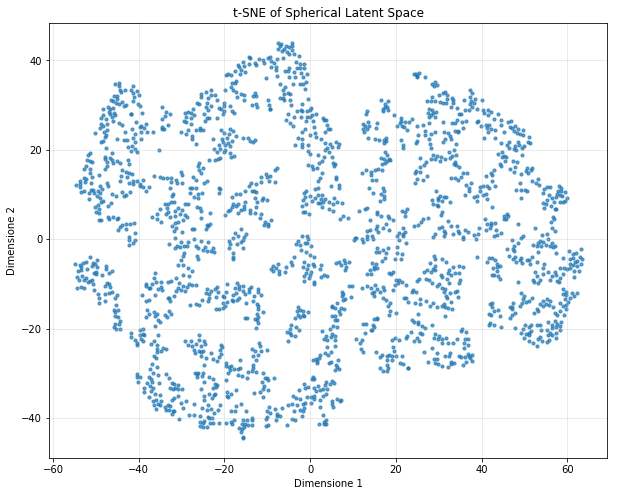

In [58]:
# def visualizza_tsne_sferico(model, device, num_points=2000):
#     print("Computing t-SNE with cosine metric...")

#     model.eval()
#     loader = DataLoader(test_dataset, batch_size=128, shuffle=True)

#     all_z = []
#     all_labels = []
#     count = 0

#     with torch.no_grad():
#         for data, labels in loader:
#             data = data.to(device).view(-1, INPUT_DIM)
#             z, *rest = model.encode(data)

#             all_z.append(z.cpu().numpy())
#             all_labels.append(labels.cpu().numpy())

#             count += len(labels)
#             if count >= num_points:
#                 break

#     X = np.concatenate(all_z, axis=0)[:num_points]
#     y = np.concatenate(all_labels, axis=0)[:num_points]

#     tsne = TSNE(n_components=2, metric='cosine', init='pca', learning_rate='auto', random_state=42)
#     X_embedded = tsne.fit_transform(X)

#     plt.figure(figsize=(10, 8))
#     scatter = plt.scatter(X_embedded[:, 0], X_embedded[:, 1], c=y, cmap='tab10', s=10, alpha=0.7)
#     plt.colorbar(scatter, ticks=range(NUM_CLASSES), label='Class')
#     plt.title("t-SNE of Spherical Latent Space")
#     plt.grid(True, alpha=0.3)
#     plt.show()

# visualizza_tsne_sferico(model_s, DEVICE, 2000)
def visualizza_tsne_sferico(model, device, num_points=2000):
    """
    Visualizza il latent space con t-SNE.
    Versione per dataset senza label, come CelebA.
    """
    print("Computing t-SNE with cosine metric...")

    model.eval()
    loader = DataLoader(test_dataset, batch_size=128, shuffle=True)

    all_z = []
    count = 0

    with torch.no_grad():
        for batch in loader:
            if isinstance(batch, (list, tuple)):
                data = batch[0]
            else:
                data = batch

            data = data.to(device)

            if hasattr(model, "fc1"):
                data_input = data.view(data.size(0), -1)
            else:
                data_input = data

            z, *rest = model.encode(data_input)

            z_np = z.detach().cpu().numpy().astype(np.float32)
            all_z.append(z_np)

            count += data.size(0)
            if count >= num_points:
                break

    X = np.concatenate(all_z, axis=0)[:num_points].astype(np.float32)

    print("Shape di X:", X.shape)
    print("Dtype di X:", X.dtype)

    tsne = TSNE(
        n_components=2,
        metric='cosine',
        init='pca',
        learning_rate=200,   # qui era 'auto'
        random_state=42
    )

    X_embedded = tsne.fit_transform(X)

    plt.figure(figsize=(10, 8))
    plt.scatter(X_embedded[:, 0], X_embedded[:, 1], s=10, alpha=0.7)
    plt.title("t-SNE of Spherical Latent Space")
    plt.xlabel("Dimensione 1")
    plt.ylabel("Dimensione 2")
    plt.grid(True, alpha=0.3)
    plt.show()

visualizza_tsne_sferico(model_s, DEVICE, 2000)


--- Sharpness comparison on 1000 generated samples ---
Real images - Mean sharpness: 0.0664 (+/- 0.0247)
------------------------------
Spherical - Mean sharpness: 0.0118 (+/- 0.0052)
Standard  - Mean sharpness: 0.0250 (+/- 0.0121)
------------------------------


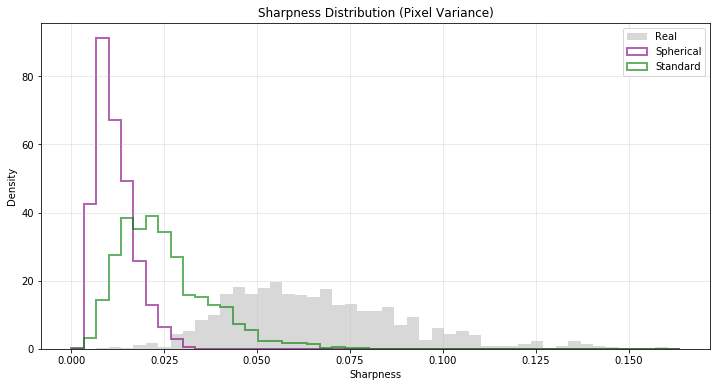

In [59]:
# def calcola_statistiche_nitidezza(images_tensor):
#     flat_images = images_tensor.view(images_tensor.size(0), -1)
#     variances = torch.var(flat_images, dim=1).cpu().numpy()
#     return variances

# def confronto_quantitativo_generazione(model_g, model_v, device, latent_dim, n_samples=1000):
#     print(f"\n--- Sharpness comparison on {n_samples} generated samples ---")

#     model_g.eval()
#     model_v.eval()

#     real_loader = DataLoader(test_dataset, batch_size=n_samples, shuffle=True)
#     real_imgs, _ = next(iter(real_loader))
#     var_real = calcola_statistiche_nitidezza(real_imgs)
#     print(f"Real images - Mean sharpness: {var_real.mean():.4f} (+/- {var_real.std():.4f})")

#     with torch.no_grad():
#         z_g = torch.randn(n_samples, latent_dim).to(device)
#         z_g = F.normalize(z_g, p=2, dim=1)
#         gen_imgs_g = model_g.decode(z_g)
#         var_g = calcola_statistiche_nitidezza(gen_imgs_g)

#         z_v = torch.randn(n_samples, latent_dim).to(device)
#         gen_imgs_v = model_v.decode(z_v)
#         var_v = calcola_statistiche_nitidezza(gen_imgs_v)

#     print("-" * 30)
#     print(f"Spherical - Mean sharpness: {var_g.mean():.4f} (+/- {var_g.std():.4f})")
#     print(f"Standard  - Mean sharpness: {var_v.mean():.4f} (+/- {var_v.std():.4f})")
#     print("-" * 30)

#     plt.figure(figsize=(12, 6))
#     bins = np.linspace(0, max(var_real.max(), var_g.max(), var_v.max()), 50)

#     plt.hist(var_real, bins=bins, alpha=0.3, color='gray', label='Real', density=True)
#     plt.hist(var_g, bins=bins, alpha=0.6, color='purple', label='Spherical', density=True, histtype='step', linewidth=2)
#     plt.hist(var_v, bins=bins, alpha=0.6, color='green', label='Standard', density=True, histtype='step', linewidth=2)

#     plt.title("Sharpness Distribution (Pixel Variance)")
#     plt.xlabel("Sharpness")
#     plt.ylabel("Density")
#     plt.legend()
#     plt.grid(True, alpha=0.3)
#     plt.show()

# confronto_quantitativo_generazione(model_s, model_v, DEVICE, LATENT_DIM, n_samples=1000)

def calcola_statistiche_nitidezza(images_tensor):
    """
    Calcola una misura semplice di nitidezza basata
    sulla varianza dei pixel di ciascuna immagine.
    """
    flat_images = images_tensor.view(images_tensor.size(0), -1)
    variances = torch.var(flat_images, dim=1).cpu().numpy()
    return variances


def confronto_quantitativo_generazione(model_g, model_v, device, latent_dim, n_samples=1000):
    """
    Confronta quantitativamente la nitidezza di:
    - immagini reali
    - immagini generate dal modello sferico
    - immagini generate dal VAE standard

    Compatibile sia con dataset con label sia senza label.
    Compatibile sia con decoder che restituiscono output flattenato
    sia con decoder che restituiscono immagini [B, C, H, W].
    """
    print(f"\n--- Sharpness comparison on {n_samples} generated samples ---")

    model_g.eval()
    model_v.eval()

    # Estrae immagini reali dal test set
    real_loader = DataLoader(test_dataset, batch_size=n_samples, shuffle=True)
    batch = next(iter(real_loader))

    # Se il dataset restituisce (data, label), prende solo le immagini
    if isinstance(batch, (list, tuple)):
        real_imgs = batch[0]
    else:
        real_imgs = batch

    # Se per qualche motivo arrivasse una singola immagine, aggiunge la batch dimension
    if real_imgs.ndim == 3:
        real_imgs = real_imgs.unsqueeze(0)

    real_imgs = real_imgs[:n_samples]
    var_real = calcola_statistiche_nitidezza(real_imgs)

    print(f"Real images - Mean sharpness: {var_real.mean():.4f} (+/- {var_real.std():.4f})")

    with torch.no_grad():
        # Campionamento sferico
        z_g = torch.randn(n_samples, latent_dim).to(device)
        z_g = F.normalize(z_g, p=2, dim=1)
        gen_imgs_g = model_g.decode(z_g).cpu()

        # Campionamento standard gaussiano
        z_v = torch.randn(n_samples, latent_dim).to(device)
        gen_imgs_v = model_v.decode(z_v).cpu()

        # Se il decoder restituisce output flattenato, lo rimodella
        if gen_imgs_g.ndim == 2:
            gen_imgs_g = gen_imgs_g.view(-1, IN_CHANNELS, IMAGE_SIZE[0], IMAGE_SIZE[1])

        if gen_imgs_v.ndim == 2:
            gen_imgs_v = gen_imgs_v.view(-1, IN_CHANNELS, IMAGE_SIZE[0], IMAGE_SIZE[1])

        var_g = calcola_statistiche_nitidezza(gen_imgs_g)
        var_v = calcola_statistiche_nitidezza(gen_imgs_v)

    print("-" * 30)
    print(f"Spherical - Mean sharpness: {var_g.mean():.4f} (+/- {var_g.std():.4f})")
    print(f"Standard  - Mean sharpness: {var_v.mean():.4f} (+/- {var_v.std():.4f})")
    print("-" * 30)

    plt.figure(figsize=(12, 6))
    bins = np.linspace(0, max(var_real.max(), var_g.max(), var_v.max()), 50)

    plt.hist(var_real, bins=bins, alpha=0.3, color='gray', label='Real', density=True)
    plt.hist(var_g, bins=bins, alpha=0.6, color='purple', label='Spherical', density=True, histtype='step', linewidth=2)
    plt.hist(var_v, bins=bins, alpha=0.6, color='green', label='Standard', density=True, histtype='step', linewidth=2)

    plt.title("Sharpness Distribution (Pixel Variance)")
    plt.xlabel("Sharpness")
    plt.ylabel("Density")
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()


confronto_quantitativo_generazione(model_s, model_v, DEVICE, LATENT_DIM, n_samples=1000)


--- Diversity analysis on 1000 generated samples ---
Real dataset diversity: 41.4719
Spherical diversity: 11.8839
Standard diversity:  25.2729
----------------------------------------
Spherical: 28.7% of real diversity
Standard : 60.9% of real diversity
----------------------------------------


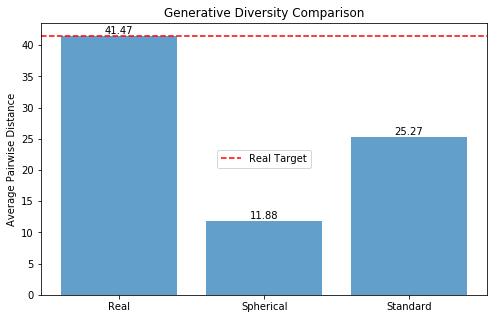

In [60]:
# #Diversity statistics
# def get_average_pairwise_distance(images_tensor):
#     flat = images_tensor.view(images_tensor.size(0), -1)
#     dists = torch.cdist(flat, flat, p=2)
#     return dists.mean().item()

# def confronto_diversita(model_g, model_v, device, latent_dim, n_samples=1000):
#     print(f"\n--- Diversity analysis on {n_samples} generated samples ---")

#     model_g.eval()
#     model_v.eval()

#     real_loader = DataLoader(test_dataset, batch_size=n_samples, shuffle=True)
#     real_imgs, _ = next(iter(real_loader))
#     real_imgs = real_imgs.to(device)

#     diversity_real = get_average_pairwise_distance(real_imgs)
#     print(f"Real dataset diversity: {diversity_real:.4f}")

#     with torch.no_grad():
#         z_g = torch.randn(n_samples, latent_dim).to(device)
#         z_g = F.normalize(z_g, p=2, dim=1)
#         gen_imgs_g = model_g.decode(z_g)
#         diversity_g = get_average_pairwise_distance(gen_imgs_g)

#         z_v = torch.randn(n_samples, latent_dim).to(device)
#         gen_imgs_v = model_v.decode(z_v)
#         diversity_v = get_average_pairwise_distance(gen_imgs_v)

#     print(f"Spherical diversity: {diversity_g:.4f}")
#     print(f"Standard diversity:  {diversity_v:.4f}")

#     perc_g = (diversity_g / diversity_real) * 100
#     perc_v = (diversity_v / diversity_real) * 100

#     print("-" * 40)
#     print(f"Spherical: {perc_g:.1f}% of real diversity")
#     print(f"Standard : {perc_v:.1f}% of real diversity")
#     print("-" * 40)

#     plt.figure(figsize=(8, 5))
#     methods = ['Real', 'Spherical', 'Standard']
#     values = [diversity_real, diversity_g, diversity_v]

#     bars = plt.bar(methods, values, alpha=0.7)
#     plt.axhline(y=diversity_real, color='red', linestyle='--', label='Real Target')

#     plt.ylabel("Average Pairwise Distance")
#     plt.title("Generative Diversity Comparison")
#     plt.legend()

#     for bar in bars:
#         yval = bar.get_height()
#         plt.text(bar.get_x() + bar.get_width()/2, yval, f"{yval:.2f}", ha='center', va='bottom')

#     plt.show()

# confronto_diversita(model_s, model_v, DEVICE, LATENT_DIM)

# Diversity statistics
def get_average_pairwise_distance(images_tensor):
    """
    Calcola la distanza euclidea media tra tutte le coppie di immagini.
    """
    flat = images_tensor.view(images_tensor.size(0), -1)
    dists = torch.cdist(flat, flat, p=2)
    return dists.mean().item()


def confronto_diversita(model_g, model_v, device, latent_dim, n_samples=1000):
    """
    Confronta la diversità tra:
    - immagini reali
    - immagini generate dal modello sferico
    - immagini generate dal VAE standard

    Compatibile con dataset con o senza label.
    Compatibile con decoder che restituiscono output flattenato
    o immagini già in formato [B, C, H, W].
    """
    print(f"\n--- Diversity analysis on {n_samples} generated samples ---")

    model_g.eval()
    model_v.eval()

    # Estrazione immagini reali
    real_loader = DataLoader(test_dataset, batch_size=n_samples, shuffle=True)
    batch = next(iter(real_loader))

    # Se il dataset restituisce (data, label), prende solo le immagini
    if isinstance(batch, (list, tuple)):
        real_imgs = batch[0]
    else:
        real_imgs = batch

    # Se arriva una singola immagine, aggiunge batch dimension
    if real_imgs.ndim == 3:
        real_imgs = real_imgs.unsqueeze(0)

    real_imgs = real_imgs[:n_samples].to(device)

    diversity_real = get_average_pairwise_distance(real_imgs)
    print(f"Real dataset diversity: {diversity_real:.4f}")

    with torch.no_grad():
        # Campionamento sferico
        z_g = torch.randn(n_samples, latent_dim).to(device)
        z_g = F.normalize(z_g, p=2, dim=1)
        gen_imgs_g = model_g.decode(z_g)

        # Campionamento standard
        z_v = torch.randn(n_samples, latent_dim).to(device)
        gen_imgs_v = model_v.decode(z_v)

        # Se il decoder restituisce output flattenato, lo rimodella
        if gen_imgs_g.ndim == 2:
            gen_imgs_g = gen_imgs_g.view(-1, IN_CHANNELS, IMAGE_SIZE[0], IMAGE_SIZE[1])

        if gen_imgs_v.ndim == 2:
            gen_imgs_v = gen_imgs_v.view(-1, IN_CHANNELS, IMAGE_SIZE[0], IMAGE_SIZE[1])

        diversity_g = get_average_pairwise_distance(gen_imgs_g)
        diversity_v = get_average_pairwise_distance(gen_imgs_v)

    print(f"Spherical diversity: {diversity_g:.4f}")
    print(f"Standard diversity:  {diversity_v:.4f}")

    perc_g = (diversity_g / diversity_real) * 100
    perc_v = (diversity_v / diversity_real) * 100

    print("-" * 40)
    print(f"Spherical: {perc_g:.1f}% of real diversity")
    print(f"Standard : {perc_v:.1f}% of real diversity")
    print("-" * 40)

    plt.figure(figsize=(8, 5))
    methods = ['Real', 'Spherical', 'Standard']
    values = [diversity_real, diversity_g, diversity_v]

    bars = plt.bar(methods, values, alpha=0.7)
    plt.axhline(y=diversity_real, color='red', linestyle='--', label='Real Target')

    plt.ylabel("Average Pairwise Distance")
    plt.title("Generative Diversity Comparison")
    plt.legend()

    for bar in bars:
        yval = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            yval,
            f"{yval:.2f}",
            ha='center',
            va='bottom'
        )

    plt.show()


confronto_diversita(model_s, model_v, DEVICE, LATENT_DIM)

In [61]:
# class RobustClassifier(nn.Module):
#     def __init__(self, num_classes):
#         super().__init__()
#         self.conv1 = nn.Conv2d(3, 32, 3, 1)   # tunnel num 3
#         self.conv2 = nn.Conv2d(32, 64, 3, 1)
#         self.dropout1 = nn.Dropout(0.25)
#         self.dropout2 = nn.Dropout(0.5)
#         self.fc1 = nn.Linear(9216, 128)
#         self.fc2 = nn.Linear(128, num_classes)

#     def forward(self, x):
#         x = self.conv1(x)
#         x = F.relu(x)
#         x = self.conv2(x)
#         x = F.relu(x)
#         x = F.max_pool2d(x, 2)
#         x = self.dropout1(x)
#         x = torch.flatten(x, 1)
#         x = self.fc1(x)
#         x = F.relu(x)
#         x = self.dropout2(x)
#         x = self.fc2(x)
#         return F.softmax(x, dim=1)

# def train_or_load_classifier(device):
#     model = RobustClassifier(NUM_CLASSES).to(device)
#     print("Training classifier for Inception-like score...")

#     optimizer = optim.Adam(model.parameters(), lr=1e-3)

#     model.train()
#     for epoch in range(3):
#         for data, target in train_loader:
#             data, target = data.to(device), target.to(device)
#             optimizer.zero_grad()
#             output = model(data)
#             loss = F.nll_loss(torch.log(output + 1e-10), target)
#             loss.backward()
#             optimizer.step()

#     model.eval()
#     print("Classifier ready.")
#     return model

# def calculate_inception_score(generated_images, classifier, device, splits=10):
#     classifier.eval()
#     preds = []

#     gen_dataset = torch.utils.data.TensorDataset(generated_images)
#     gen_loader = DataLoader(gen_dataset, batch_size=100)

#     with torch.no_grad():
#         for batch in gen_loader:
#             batch_imgs = batch[0].to(device)
#             pred = classifier(batch_imgs)
#             preds.append(pred.cpu().numpy())

#     preds = np.concatenate(preds, axis=0)
#     scores = []
#     n_part = preds.shape[0] // splits

#     for i in range(splits):
#         part = preds[i * n_part : (i + 1) * n_part]
#         p_y = np.expand_dims(np.mean(part, axis=0), 0)

#         kl_div = part * (np.log(part + 1e-16) - np.log(p_y + 1e-16))
#         kl_div = np.sum(kl_div, axis=1)
#         avg_kl = np.mean(kl_div)

#         scores.append(np.exp(avg_kl))

#     return np.mean(scores), np.std(scores)

# def confronta_inception_score(model_g, model_v, device, latent_dim, n_samples=2000):
#     print(f"\n--- Inception-like Score on {n_samples} generated samples ---")

#     judge = train_or_load_classifier(device)

#     model_g.eval()
#     model_v.eval()

#     with torch.no_grad():
#         z_g = torch.randn(n_samples, latent_dim).to(device)
#         z_g = F.normalize(z_g, p=2, dim=1)
#         imgs_g = model_g.decode(z_g).view(-1, 3, 28, 28)   # tunnel num 3

#         z_v = torch.randn(n_samples, latent_dim).to(device)
#         imgs_v = model_v.decode(z_v).view(-1, 3, 28, 28)   # tunnel num 3

#     print("Calculating score for spherical model...")
#     mean_g, std_g = calculate_inception_score(imgs_g, judge, device)

#     print("Calculating score for standard model...")
#     mean_v, std_v = calculate_inception_score(imgs_v, judge, device)

#     print("-" * 40)
#     print(f"Spherical: {mean_g:.4f} +/- {std_g:.4f}")
#     print(f"Standard : {mean_v:.4f} +/- {std_v:.4f}")
#     print("-" * 40)

#     labels = ['Spherical', 'Standard']
#     means = [mean_g, mean_v]
#     errors = [std_g, std_v]

#     plt.figure(figsize=(8, 6))
#     plt.bar(labels, means, yerr=errors, capsize=10, alpha=0.7)
#     plt.ylabel("Inception-like Score")
#     plt.title("Inception-like Score Comparison")
#     plt.grid(axis='y', alpha=0.3)
#     plt.show()

# confronta_inception_score(model_s, model_v, DEVICE, LATENT_DIM)

In [62]:


class InceptionFeatureExtractor(nn.Module):
    """
    Estrae feature da InceptionV3 pre-addestrata.
    Compatibile con versioni meno recenti di torchvision.
    """
    def __init__(self, device):
        super().__init__()
        self.model = inception_v3(pretrained=True, transform_input=False)
        self.model.fc = nn.Identity()
        self.model.eval()
        self.model.to(device)

    def forward(self, x):
        if x.shape[1] == 1:
            x = x.repeat(1, 3, 1, 1)

        x = F.interpolate(x, size=(299, 299), mode='bilinear', align_corners=False)

        mean = torch.tensor([0.485, 0.456, 0.406], device=x.device).view(1, 3, 1, 1)
        std = torch.tensor([0.229, 0.224, 0.225], device=x.device).view(1, 3, 1, 1)
        x = (x - mean) / std

        with torch.no_grad():
            feat = self.model(x)

        return feat


def get_real_images_from_loader(loader, n_samples, device):
    imgs = []
    collected = 0

    for batch in loader:
        if isinstance(batch, (list, tuple)):
            data = batch[0]
        else:
            data = batch

        imgs.append(data)
        collected += data.size(0)

        if collected >= n_samples:
            break

    imgs = torch.cat(imgs, dim=0)[:n_samples].to(device)
    return imgs


def get_generated_images(model, latent_dim, n_samples, device):
    model.eval()

    with torch.no_grad():
        model_name = model.__class__.__name__.lower()

        if "spherical" in model_name or "geodesic" in model_name:
            z = torch.randn(n_samples, latent_dim, device=device)
            z = F.normalize(z, p=2, dim=1)
        else:
            z = torch.randn(n_samples, latent_dim, device=device)

        imgs = model.decode(z)

        if imgs.ndim == 2:
            imgs = imgs.view(-1, IN_CHANNELS, IMAGE_SIZE[0], IMAGE_SIZE[1])

        imgs = imgs.clamp(0, 1)

    return imgs


def get_activations(images, feature_extractor, batch_size=64):
    acts = []

    for i in range(0, images.size(0), batch_size):
        batch = images[i:i + batch_size]
        feat = feature_extractor(batch)
        acts.append(feat.cpu().numpy())

    acts = np.concatenate(acts, axis=0).astype(np.float64)
    return acts


def compute_statistics(activations):
    mu = np.mean(activations, axis=0)
    sigma = np.cov(activations, rowvar=False)
    return mu, sigma


def calculate_fid(mu1, sigma1, mu2, sigma2, eps=1e-6):
    diff = mu1 - mu2

    covmean = sqrtm(sigma1 @ sigma2)

    if not np.isfinite(covmean).all():
        offset = np.eye(sigma1.shape[0]) * eps
        covmean = sqrtm((sigma1 + offset) @ (sigma2 + offset))

    if np.iscomplexobj(covmean):
        covmean = covmean.real

    fid = diff @ diff + np.trace(sigma1 + sigma2 - 2 * covmean)
    return float(fid)


def compute_fid_for_model(model, real_loader, latent_dim, n_samples, device, feature_extractor):
    print(f"Estrazione di {n_samples} immagini reali...")
    real_imgs = get_real_images_from_loader(real_loader, n_samples, device)

    print(f"Generazione di {n_samples} immagini sintetiche...")
    fake_imgs = get_generated_images(model, latent_dim, n_samples, device)

    print("Estrazione feature Inception per immagini reali...")
    real_acts = get_activations(real_imgs, feature_extractor)

    print("Estrazione feature Inception per immagini generate...")
    fake_acts = get_activations(fake_imgs, feature_extractor)

    mu_real, sigma_real = compute_statistics(real_acts)
    mu_fake, sigma_fake = compute_statistics(fake_acts)

    fid = calculate_fid(mu_real, sigma_real, mu_fake, sigma_fake)
    return fid


def confronta_fid_celeba(model_s, model_v, real_loader, latent_dim, device, n_samples=2000):
    print(f"\n--- FID su {n_samples} campioni generati (CelebA senza label) ---")

    feature_extractor = InceptionFeatureExtractor(device)

    print("\nCalcolo FID per il modello sferico...")
    fid_s = compute_fid_for_model(
        model=model_s,
        real_loader=real_loader,
        latent_dim=latent_dim,
        n_samples=n_samples,
        device=device,
        feature_extractor=feature_extractor
    )

    print("\nCalcolo FID per il VAE standard...")
    fid_v = compute_fid_for_model(
        model=model_v,
        real_loader=real_loader,
        latent_dim=latent_dim,
        n_samples=n_samples,
        device=device,
        feature_extractor=feature_extractor
    )

    print("-" * 40)
    print(f"FID Modello Sferico : {fid_s:.4f}")
    print(f"FID VAE Standard    : {fid_v:.4f}")
    print("-" * 40)
    print("Nota: un valore FID più basso indica una migliore qualità generativa.")

    labels = ["Sferico", "Standard"]
    values = [fid_s, fid_v]

    plt.figure(figsize=(8, 6))
    bars = plt.bar(labels, values, alpha=0.7)
    plt.ylabel("FID")
    plt.title("Confronto FID tra i due modelli su CelebA")
    plt.grid(axis="y", alpha=0.3)

    for bar in bars:
        yval = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            yval,
            f"{yval:.2f}",
            ha="center",
            va="bottom"
        )

    plt.show()

    return fid_s, fid_v


fid_s, fid_v = confronta_fid_celeba(
    model_s,
    model_v,
    test_loader,
    LATENT_DIM,
    DEVICE,
    n_samples=2000
)


--- FID su 2000 campioni generati (CelebA senza label) ---


NameError: name 'inception_v3' is not defined